In [3]:
import pandas as pd
df = pd.read_csv("used_cars.csv")
print(df.shape) # (4009, 12)
print(df.dtypes)
print(df.isnull().sum())

(4009, 12)
brand           object
model           object
model_year       int64
milage          object
fuel_type       object
engine          object
transmission    object
ext_col         object
int_col         object
accident        object
clean_title     object
price           object
dtype: object
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [4]:
# Bersihkan milage: "51,000 mi." -> 51000
df["milage"] = df["milage"].str.replace(" mi.", "", regex=False)
df["milage"] = df["milage"].str.replace(",", "", regex=False)
df["milage"] = pd.to_numeric(df["milage"], errors="coerce")
# Bersihkan price: "$10,300" -> 10300
df["price"] = df["price"].str.replace("$", "", regex=False)
df["price"] = df["price"].str.replace(",", "", regex=False)
df["price"] = pd.to_numeric(df["price"], errors="coerce")
# Drop missing values
df = df.dropna(subset=["milage", "price"]).copy()
# Filter outlier ekstrem
df = df[(df["price"] <= 150000) & (df["milage"] <= 300000)]
print(df.shape) # (3886, 12)

(3886, 12)


-0.6103704757421622


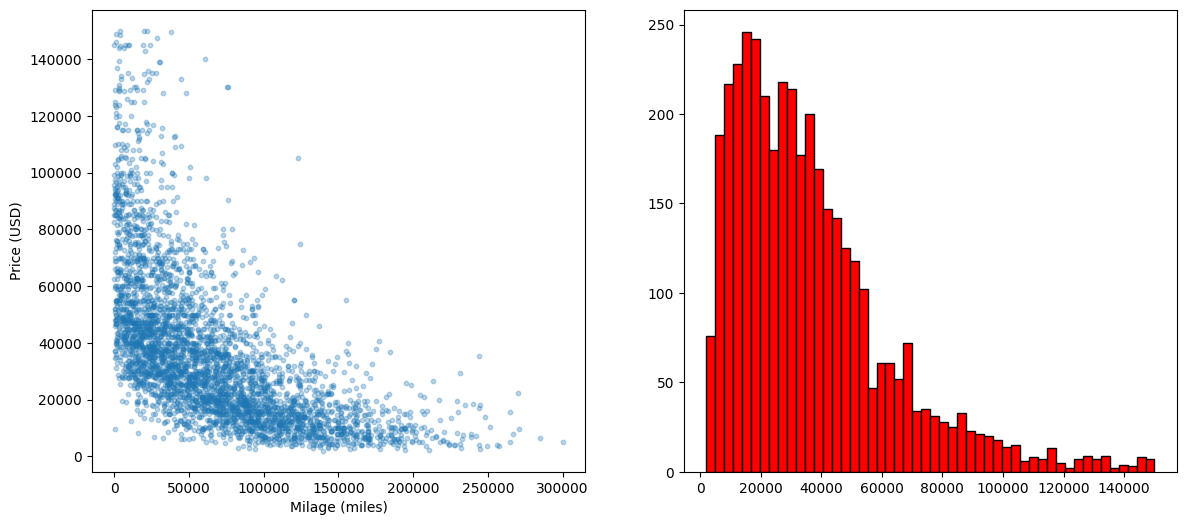

In [12]:
# Scatterplot & distribusi
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(df["milage"], df["price"], alpha=0.3, s=10)
axes[0].set_xlabel("Milage (miles)"); axes[0].set_ylabel("Price (USD)")
axes[1].hist(df["price"], bins=50, color="#FF0000",edgecolor='black')
plt.savefig("eda_plot.png", dpi=150)
# Korelasi
print(df["milage"].corr(df["price"])) # -0.31

In [6]:
from sklearn.model_selection import train_test_split
X = df[["milage"]]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)

In [7]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(f"Intercept: {model.intercept_:.4f}")
print(f"Koefisien: {model.coef_[0]:.4f}")

Intercept: 56720.3903
Koefisien: -0.3098


In [8]:
from sklearn import metrics
import numpy as np
y_pred = model.predict(X_test)
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, y_pred)
print(f"MAE : ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2 : {r2:.4f}")

MAE : $15,341.41
RMSE: $20,498.00
R2 : 0.4073


In [9]:
import joblib
joblib.dump(model, "model_used_cars.pkl")
# Verifikasi
loaded = joblib.load("model_used_cars.pkl")
print(loaded.predict([[50000]])) # [41229.32]

[41229.32481014]


c:\Users\ADVAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
